In [1]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import folium
# set display columns to max so that we can view all columns
pd.set_option('display.max_columns', None)

In [2]:
data = pd.read_csv("data/raw/US_Accidents_March23_NJ.csv")

In [3]:
data_nj = data.copy()

In [4]:
data.head()

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Description,Street,City,County,State,Zipcode,Country,Timezone,Airport_Code,Weather_Timestamp,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-194257,Source2,3,2016-11-30 16:25:41,2016-11-30 17:10:30,41.139324,-74.169876,NaN,NaN,0.01,Right lane blocked due to accident on I-87 Sou...,Route 17,Sloatsburg,Rockland,NY,10974,US,US/Eastern,KCDW,2016-11-30 16:53:00,53.1,NaN,93.0,29.81,1.0,East,11.5,0.00,Overcast,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
1,A-194258,Source2,3,2016-11-30 15:40:06,2016-11-30 17:09:40,41.118748,-74.159744,NaN,NaN,2.53,Accident on I-87 Southbound between Exit 14B C...,I-287 S,Suffern,Rockland,NY,10901,US,US/Eastern,KCDW,2016-11-30 15:53:00,53.1,NaN,93.0,29.83,1.0,ENE,8.1,0.02,Overcast,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
2,A-194259,Source2,3,2016-11-30 15:26:18,2016-11-30 16:56:02,41.014034,-73.717239,NaN,NaN,1.17,Accident on I-287 Cross Westchester Expy Eastb...,Hutchinson River Pkwy S,White Plains,Westchester,NY,10605,US,US/Eastern,KHPN,2016-11-30 15:56:00,52.0,NaN,93.0,29.81,2.0,East,17.3,0.15,Light Rain,False,False,False,False,True,False,False,False,False,False,False,False,False,Day,Day,Day,Day
3,A-194260,Source2,3,2016-11-30 16:14:11,2016-11-30 16:59:00,41.390369,-73.597969,NaN,NaN,0.01,Right hand shoulder blocked due to accident on...,I-84 E,Brewster,Putnam,NY,10509,US,US/Eastern,KDXR,2016-11-30 15:53:00,52.0,NaN,89.0,29.86,3.0,East,10.4,0.05,Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
4,A-194261,Source2,3,2016-11-30 16:17:57,2016-11-30 17:02:44,41.390369,-73.597969,NaN,NaN,0.01,Right hand shoulder blocked due to accident on...,I-84 E,Brewster,Putnam,NY,10509,US,US/Eastern,KDXR,2016-11-30 15:53:00,52.0,NaN,89.0,29.86,3.0,East,10.4,0.05,Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day


In [5]:
data.shape

(347960, 46)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 347960 entries, 0 to 347959
Data columns (total 46 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   ID                     347960 non-null  object 
 1   Source                 347960 non-null  object 
 2   Severity               347960 non-null  int64  
 3   Start_Time             347960 non-null  object 
 4   End_Time               347960 non-null  object 
 5   Start_Lat              347960 non-null  float64
 6   Start_Lng              347960 non-null  float64
 7   End_Lat                194902 non-null  float64
 8   End_Lng                194902 non-null  float64
 9   Distance(mi)           347960 non-null  float64
 10  Description            347959 non-null  object 
 11  Street                 347312 non-null  object 
 12  City                   347932 non-null  object 
 13  County                 347960 non-null  object 
 14  State                  347960 non-nu

## Exploratory Data Analysis (EDA)

This section performs initial exploratory analysis on the New Jersey accidents dataset. It includes:
- Data shape and brief preview
- Missing value summary
- Target (Severity) distribution
- Time-based features (hour, weekday)
- Numeric correlations
- Top cities/counties/streets
- A small sample map saved to `data/raw/accidents_map_sample.html` #### need to check this


In [7]:
data = pd.read_csv("data/raw/US_Accidents_March23_NJ.csv", index_col='id')

print("Shape:", data.shape)
print('\nColumns:')
print(list(data.columns))

# show head
display(data.head())

# basic info
print('\nInfo:')
data.info()

# basic describe for numeric
print('\nNumeric summary (describe):')
display(data.describe(include=[np.number]).T)

Shape: (347960, 46)

Columns:
['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat', 'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description', 'Street', 'City', 'County', 'State', 'Zipcode', 'Country', 'Timezone', 'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction', 'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway', 'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal', 'Turning_Loop', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight', 'Astronomical_Twilight']


,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Description,Street,City,County,State,Zipcode,Country,Timezone,Airport_Code,Weather_Timestamp,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-194257,Source2,3,2016-11-30 16:25:41,2016-11-30 17:10:30,41.139324,-74.169876,NaN,NaN,0.01,Right lane blocked due to accident on I-87 Sou...,Route 17,Sloatsburg,Rockland,NY,10974,US,US/Eastern,KCDW,2016-11-30 16:53:00,53.1,NaN,93.0,29.81,1.0,East,11.5,0.00,Overcast,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
1,A-194258,Source2,3,2016-11-30 15:40:06,2016-11-30 17:09:40,41.118748,-74.159744,NaN,NaN,2.53,Accident on I-87 Southbound between Exit 14B C...,I-287 S,Suffern,Rockland,NY,10901,US,US/Eastern,KCDW,2016-11-30 15:53:00,53.1,NaN,93.0,29.83,1.0,ENE,8.1,0.02,Overcast,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
2,A-194259,Source2,3,2016-11-30 15:26:18,2016-11-30 16:56:02,41.014034,-73.717239,NaN,NaN,1.17,Accident on I-287 Cross Westchester Expy Eastb...,Hutchinson River Pkwy S,White Plains,Westchester,NY,10605,US,US/Eastern,KHPN,2016-11-30 15:56:00,52.0,NaN,93.0,29.81,2.0,East,17.3,0.15,Light Rain,False,False,False,False,True,False,False,False,False,False,False,False,False,Day,Day,Day,Day
3,A-194260,Source2,3,2016-11-30 16:14:11,2016-11-30 16:59:00,41.390369,-73.597969,NaN,NaN,0.01,Right hand shoulder blocked due to accident on...,I-84 E,Brewster,Putnam,NY,10509,US,US/Eastern,KDXR,2016-11-30 15:53:00,52.0,NaN,89.0,29.86,3.0,East,10.4,0.05,Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
4,A-194261,Source2,3,2016-11-30 16:17:57,2016-11-30 17:02:44,41.390369,-73.597969,NaN,NaN,0.01,Right hand shoulder blocked due to accident on...,I-84 E,Brewster,Putnam,NY,10509,US,US/Eastern,KDXR,2016-11-30 15:53:00,52.0,NaN,89.0,29.86,3.0,East,10.4,0.05,Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day



Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 347960 entries, 0 to 347959
Data columns (total 46 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   ID                     347960 non-null  object 
 1   Source                 347960 non-null  object 
 2   Severity               347960 non-null  int64  
 3   Start_Time             347960 non-null  object 
 4   End_Time               347960 non-null  object 
 5   Start_Lat              347960 non-null  float64
 6   Start_Lng              347960 non-null  float64
 7   End_Lat                194902 non-null  float64
 8   End_Lng                194902 non-null  float64
 9   Distance(mi)           347960 non-null  float64
 10  Description            347959 non-null  object 
 11  Street                 347312 non-null  object 
 12  City                   347932 non-null  object 
 13  County                 347960 non-null  object 
 14  State                  347960

,count,mean,std,min,25%,50%,75%,max
Severity,347960.0,2.259550,0.511014,1.000000,2.000000,2.000000,2.000000,4.000000
Start_Lat,347960.0,41.560975,0.999105,40.503048,40.758131,40.976681,42.743330,45.001892
Start_Lng,347960.0,-74.556611,1.574805,-79.761920,-74.088270,-73.894638,-73.760542,-71.861031
End_Lat,194902.0,41.536836,0.999496,40.505200,40.750500,40.918790,42.714843,44.997320
End_Lng,194902.0,-74.526908,1.528085,-79.761981,-74.076729,-73.903030,-73.769342,-71.943680
Distance(mi),347960.0,0.751562,2.124309,0.000000,0.000000,0.069000,0.713000,112.903000
Temperature(F),345892.0,54.840956,19.336263,-77.800000,39.000000,56.000000,71.000000,172.000000
Wind_Chill(F),276306.0,49.544803,23.010782,-39.000000,31.000000,52.000000,69.000000,172.000000
Humidity(%),345769.0,65.880507,20.201403,1.000000,50.000000,66.000000,84.000000,100.000000
Pressure(in),344976.0,29.813697,0.382717,19.750000,29.600000,29.870000,30.070000,30.890000


In [8]:
# Missing values summary
missing = data.isnull().sum().sort_values(ascending=False)
print('Columns with missing values (top 30):')
display(missing[missing > 0].head(30))

# Fraction missing
miss_frac = (data.isnull().mean() * 100).sort_values(ascending=False)
display(miss_frac[miss_frac > 0].head(30))

Columns with missing values (top 30):


End_Lat                  153058
End_Lng                  153058
Precipitation(in)         86511
Wind_Chill(F)             71654
Wind_Speed(mph)           17879
Wind_Direction             4477
Visibility(mi)             3081
Pressure(in)               2984
Weather_Condition          2726
Humidity(%)                2191
Temperature(F)             2068
Weather_Timestamp          1459
Nautical_Twilight           710
Civil_Twilight              710
Sunrise_Sunset              710
Astronomical_Twilight       710
Street                      648
Airport_Code                347
City                         28
Description                   1
dtype: int64

End_Lat                  43.987240
End_Lng                  43.987240
Precipitation(in)        24.862340
Wind_Chill(F)            20.592597
Wind_Speed(mph)           5.138234
Wind_Direction            1.286642
Visibility(mi)            0.885447
Pressure(in)              0.857570
Weather_Condition         0.783423
Humidity(%)               0.629670
Temperature(F)            0.594321
Weather_Timestamp         0.419301
Nautical_Twilight         0.204046
Civil_Twilight            0.204046
Sunrise_Sunset            0.204046
Astronomical_Twilight     0.204046
Street                    0.186228
Airport_Code              0.099724
City                      0.008047
Description               0.000287
dtype: float64

In [9]:
# Data Preparations
# *******************
# feature transformation

# Convert Start_Time to datetime
data['Start_Time'] = pd.to_datetime(data['Start_Time'])
data['End_Time'] = pd.to_datetime(data['End_Time'])

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
import calendar

In [11]:
# sns.set(style="whitegrid")

### Univariate analysis:

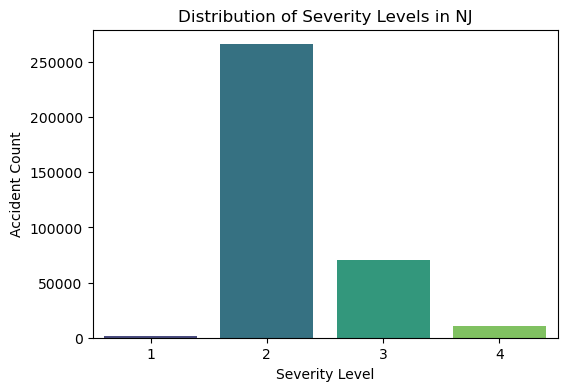


Severity counts:


2    265902
3     70062
4     10749
1      1247
Name: Severity, dtype: int64

In [12]:
# 1. Distribution of Severity Levels
plt.figure(figsize=(6,4))
sns.countplot(x='Severity', data=data, palette='viridis')
plt.title('Distribution of Severity Levels in NJ')
plt.xlabel('Severity Level')
plt.ylabel('Accident Count')
plt.show()
print('\nSeverity counts:')
display(data['Severity'].value_counts())

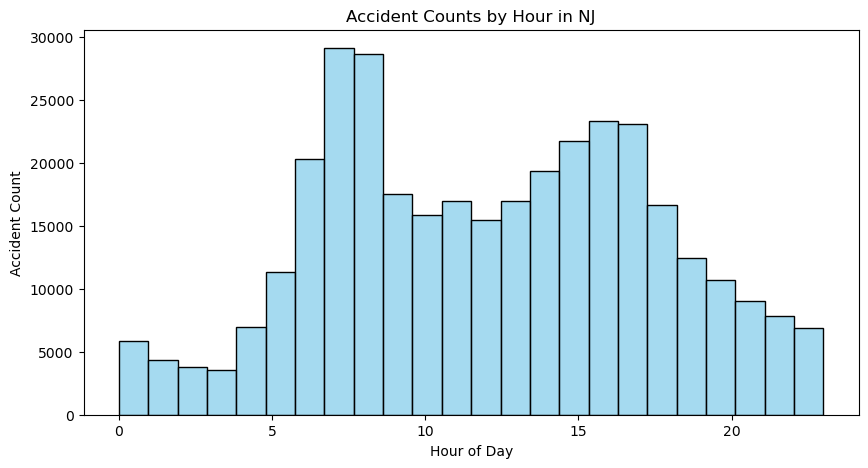

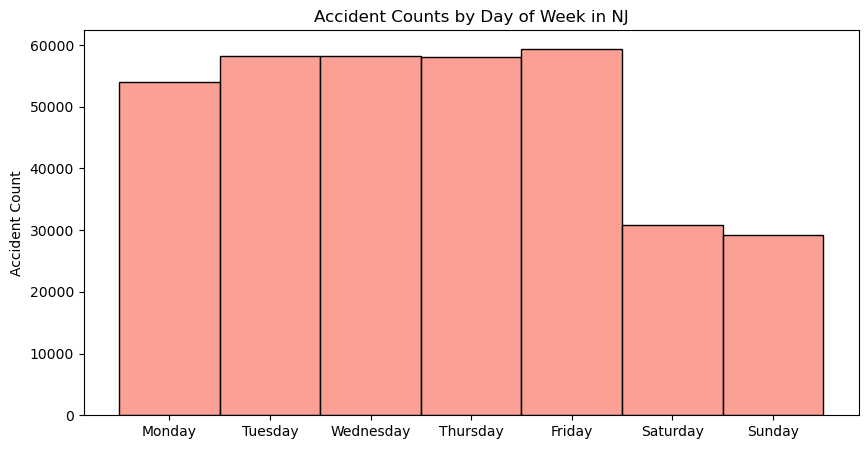

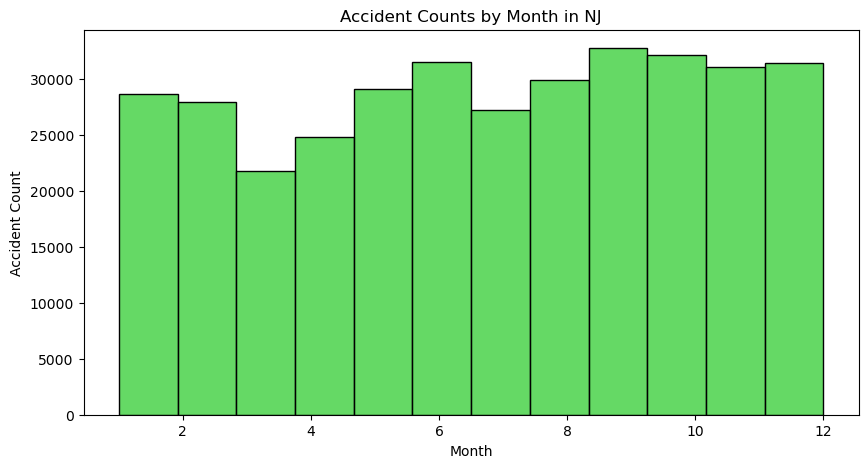

In [13]:
# 2 Accident Counts by Hour, Day, Month


# Hour
plt.figure(figsize=(10, 5))
sns.histplot(data['Start_Time'].dt.hour, bins=24, kde=False, color='skyblue')
plt.title('Accident Counts by Hour in NJ')
plt.xlabel('Hour of Day')
plt.ylabel('Accident Count')
plt.show()

# The chart shows that traffic accidents in New Jersey follow a clear daily pattern.
# Accidents are rare during the early morning hours (midnight to 5 AM), then spike sharply during the morning commute (7–9 AM). 
# There's a midday dip followed by another rise during the afternoon rush (3–6 PM) and then a gradual decline into the evening.

# Day of Week
plt.figure(figsize=(10, 5))
data['Weekday'] = data['Start_Time'].dt.dayofweek.map(lambda x: calendar.day_name[x])
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
# Define weekday order
weekday_order = list(calendar.day_name)
data['Weekday'] = pd.Categorical(data['Weekday'], categories=order, ordered=True)

sns.histplot(data,x= "Weekday", bins=7, kde=False, color='salmon')
plt.title('Accident Counts by Day of Week in NJ')
plt.xlabel('')
plt.ylabel('Accident Count')
plt.show()


# Month
plt.figure(figsize=(10, 5))
sns.histplot(data['Start_Time'].dt.month, bins=12, kde=False, color='limegreen')
plt.title('Accident Counts by Month in NJ')
plt.xlabel('Month')
plt.ylabel('Accident Count')
plt.show()

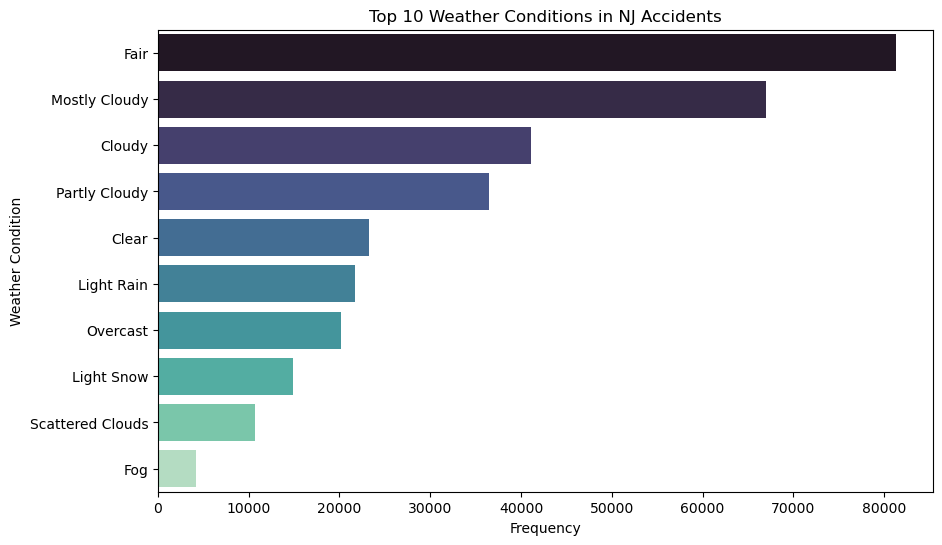

In [14]:

# 3 Weather Condition Frequencies (Top 10)
top_weather = data['Weather_Condition'].value_counts().nlargest(10)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_weather.values, y=top_weather.index, palette='mako')
plt.title('Top 10 Weather Conditions in NJ Accidents')
plt.xlabel('Frequency')
plt.ylabel('Weather Condition')
plt.show()

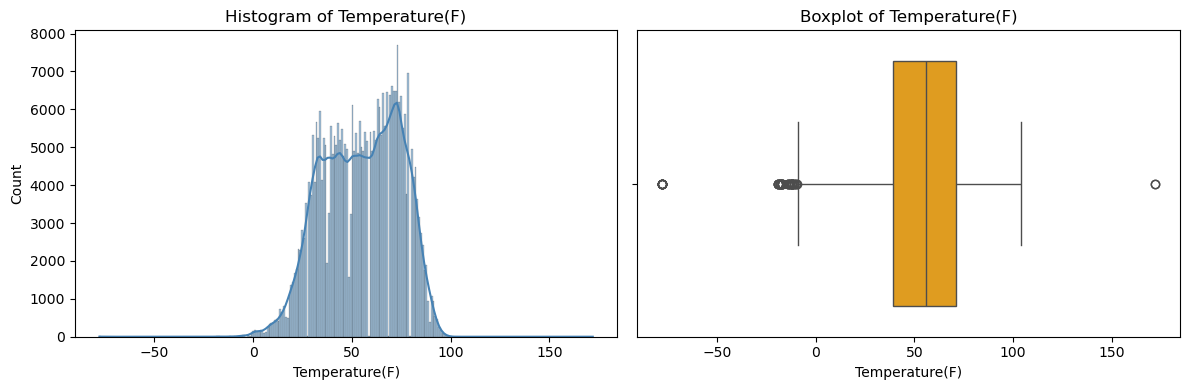

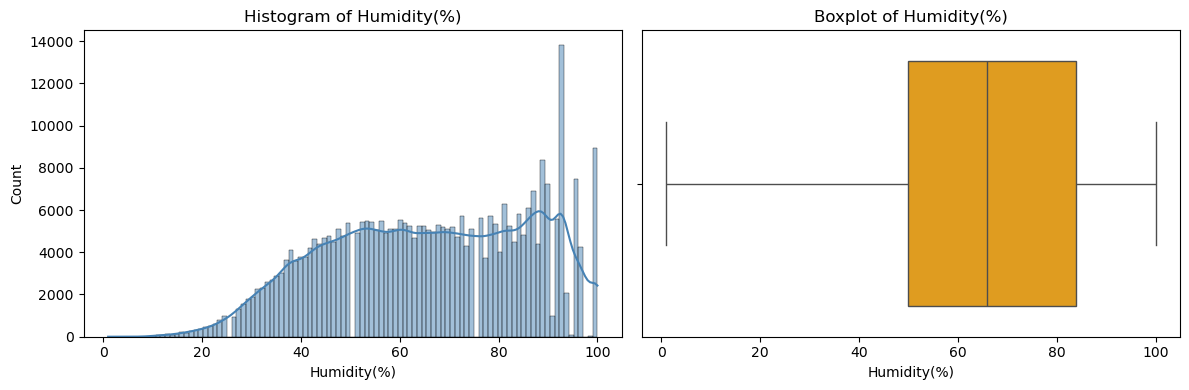

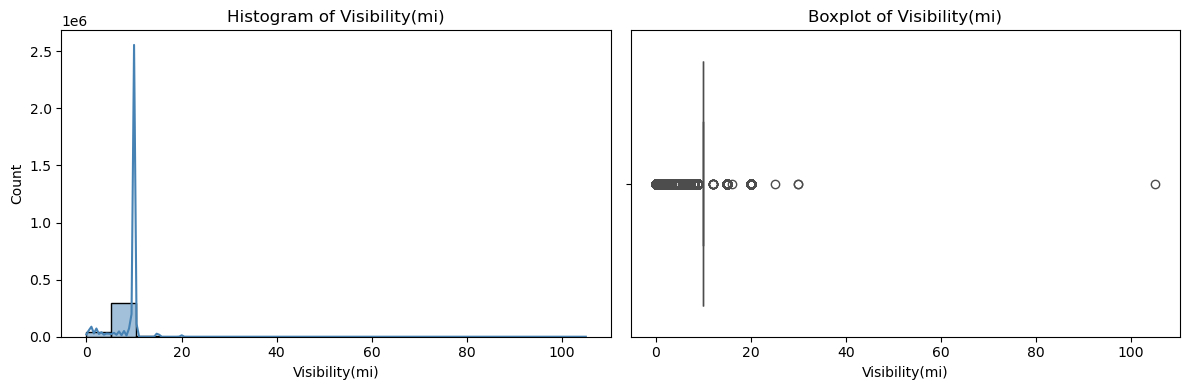

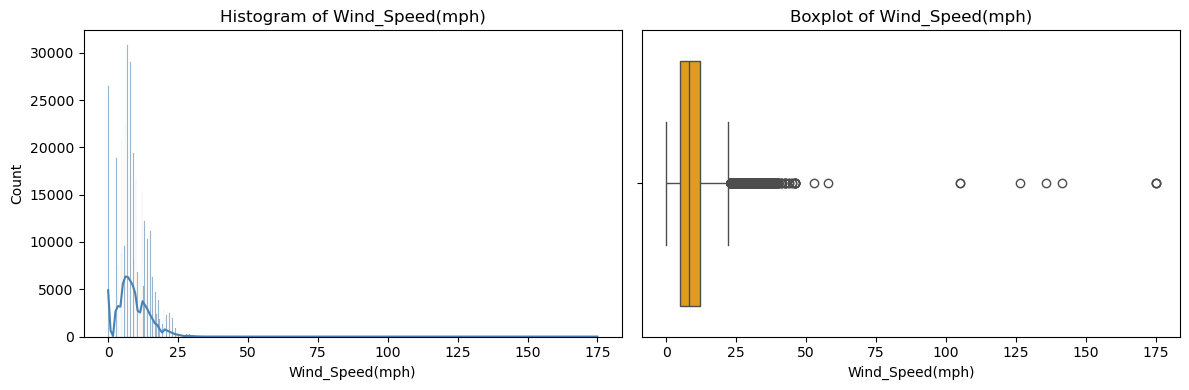

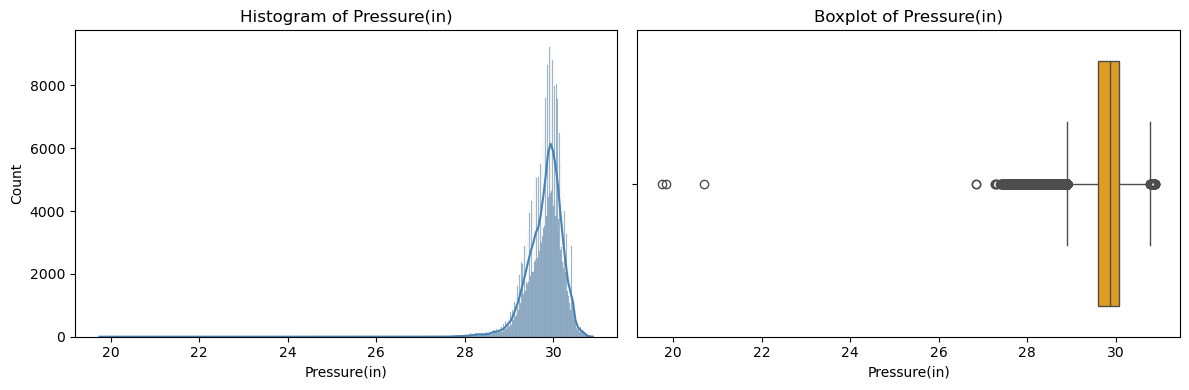

In [15]:
# 4 Numeric Features: Histograms and Boxplots
numeric_cols = ['Temperature(F)', 'Humidity(%)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Pressure(in)']

for col in numeric_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    # Histogram
    sns.histplot(data[col].dropna(), ax=axes[0], kde=True, color='steelblue')
    axes[0].set_title(f'Histogram of {col}')
    
    # Boxplot
    sns.boxplot(x=data[col].dropna(), ax=axes[1], color='orange')
    axes[1].set_title(f'Boxplot of {col}')
    
    plt.tight_layout()
    plt.show()

### Bivariate analysis:

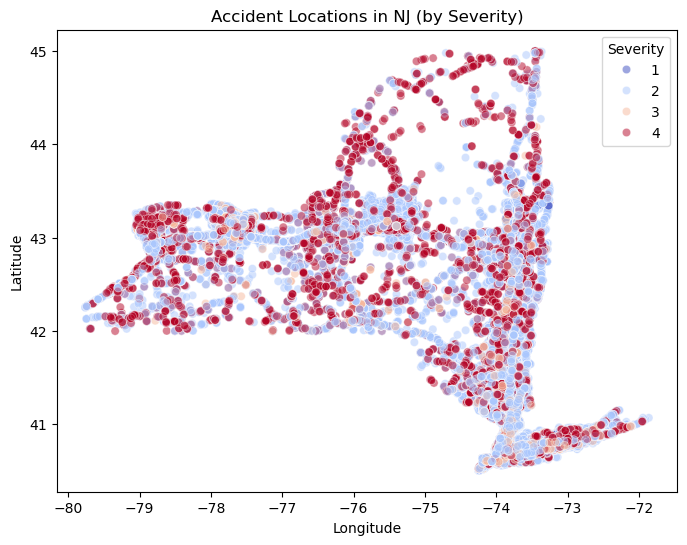

In [16]:
# 1 Scatter Plot: Latitude vs Longitude
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Start_Lng', y='Start_Lat', data=data, hue='Severity', palette='coolwarm', alpha=0.5)
plt.title('Accident Locations in NJ (by Severity)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(title='Severity', loc='upper right')
plt.show()

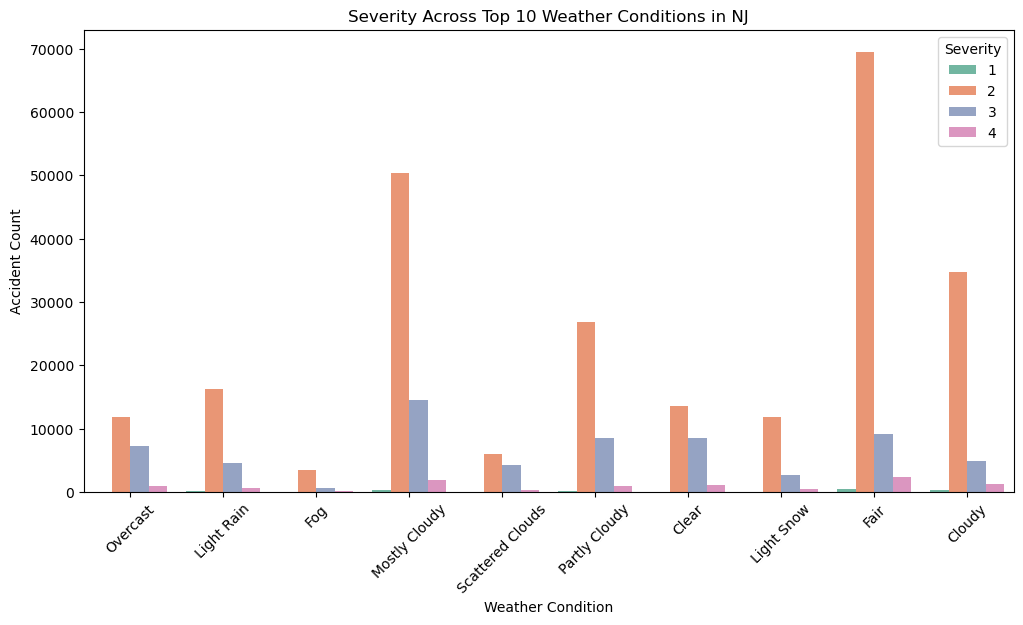

In [17]:
# 2 Severity vs Weather Conditions (Grouped Bar Chart)
top_weather = data['Weather_Condition'].value_counts().nlargest(10).index
df_weather = data[data['Weather_Condition'].isin(top_weather)]

plt.figure(figsize=(12, 6))
sns.countplot(data=df_weather, x='Weather_Condition', hue='Severity', palette='Set2')
plt.title('Severity Across Top 10 Weather Conditions in NJ')
plt.xlabel('Weather Condition')
plt.ylabel('Accident Count')
plt.xticks(rotation=45)
plt.legend(title='Severity')
plt.show()

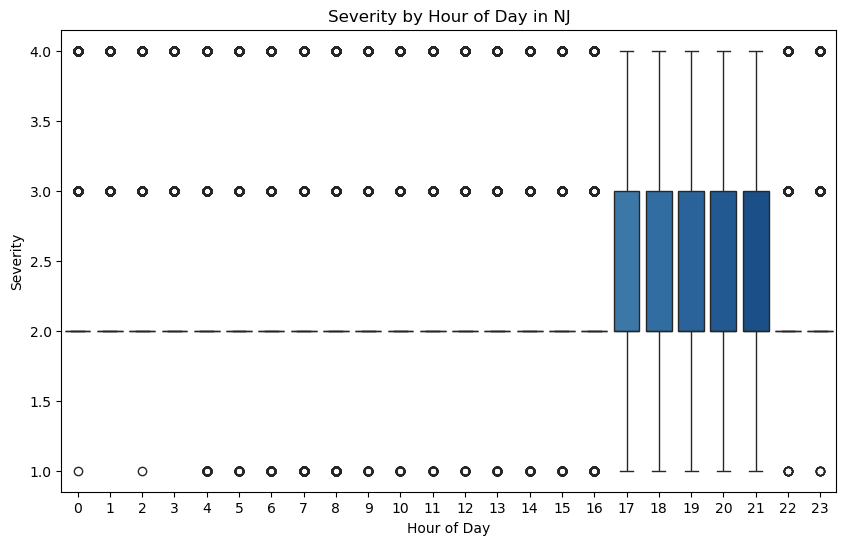

In [18]:
# 3 Severity vs Time of Day (Boxplot by Hour)
data['Hour'] = data['Start_Time'].dt.hour

plt.figure(figsize=(10, 6))
sns.boxplot(x='Hour', y='Severity', data=data, palette='Blues')
plt.title('Severity by Hour of Day in NJ')
plt.xlabel('Hour of Day')
plt.ylabel('Severity')
plt.show()

In [19]:
data.groupby('Hour')['Severity'].describe()

,count,mean,std,min,25%,50%,75%,max
Hour,,,,,,,,
0,5869.0,2.319646,0.609562,1.0,2.0,2.0,2.0,4.0
1,4345.0,2.246490,0.548522,2.0,2.0,2.0,2.0,4.0
2,3812.0,2.291186,0.587811,1.0,2.0,2.0,2.0,4.0
3,3567.0,2.303897,0.584089,2.0,2.0,2.0,2.0,4.0
4,7009.0,2.258810,0.544603,1.0,2.0,2.0,2.0,4.0
5,11335.0,2.261491,0.529102,1.0,2.0,2.0,2.0,4.0
6,20308.0,2.220898,0.479503,1.0,2.0,2.0,2.0,4.0
7,29132.0,2.212996,0.463688,1.0,2.0,2.0,2.0,4.0
8,28644.0,2.229856,0.469234,1.0,2.0,2.0,2.0,4.0


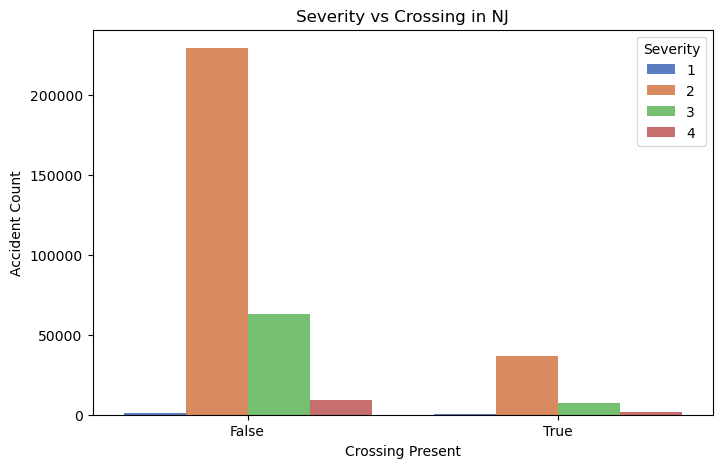

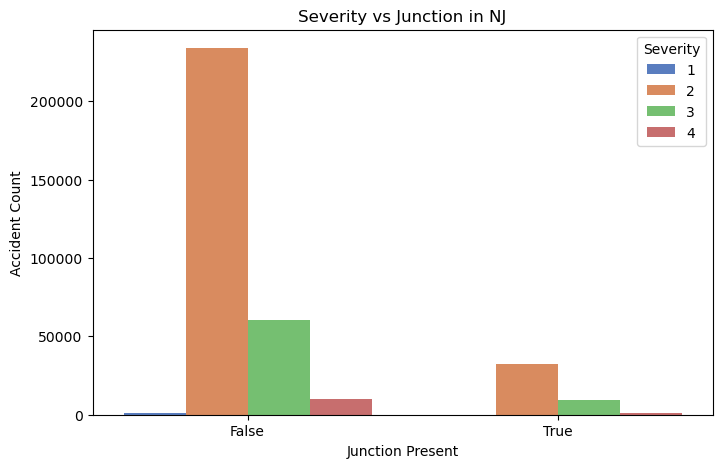

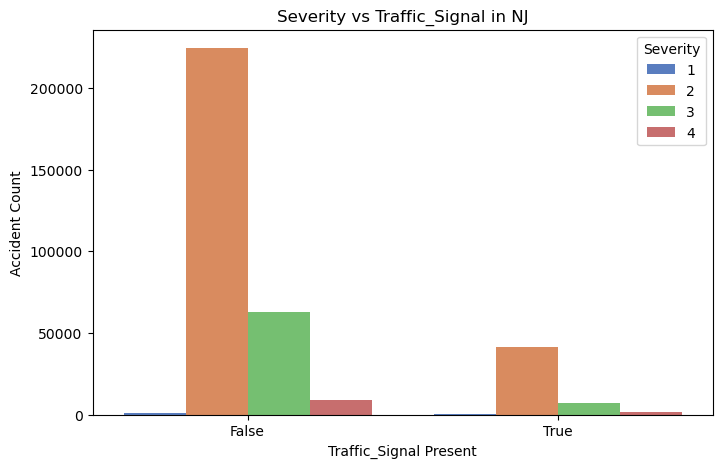

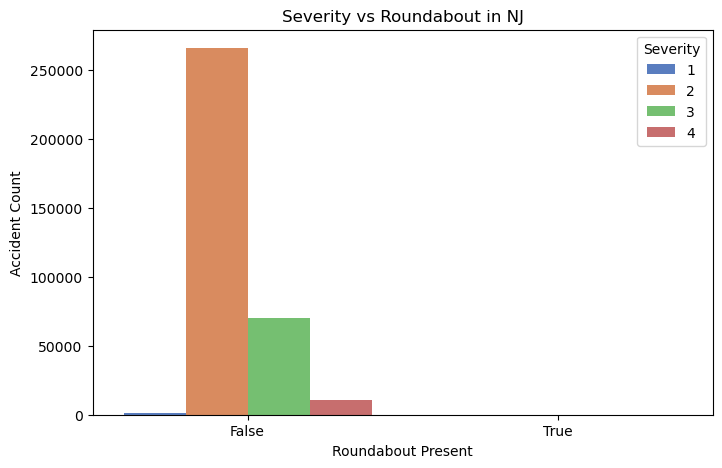

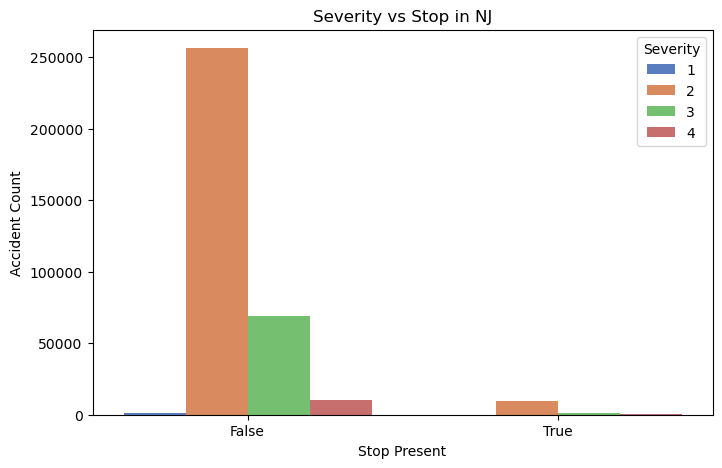

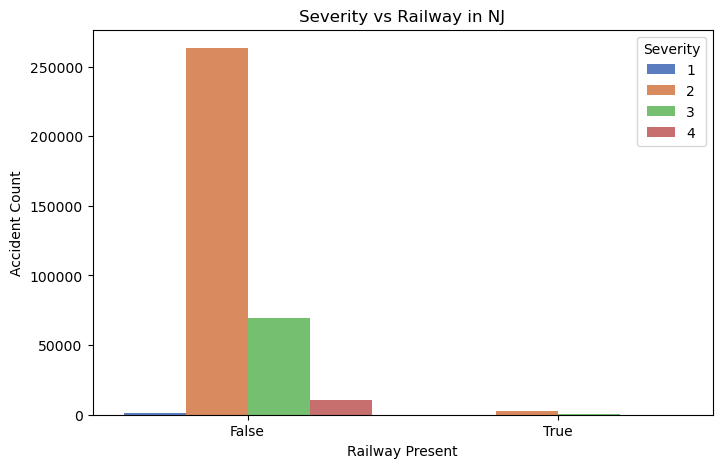

In [20]:
# 4 Severity vs Road Infrastructure Features
# Select relevant infrastructure features
infra_features = ['Crossing', 'Junction', 'Traffic_Signal', 'Roundabout', 'Stop', 'Railway']

for feature in infra_features:
    plt.figure(figsize=(8, 5))
    sns.countplot(data=data, x=feature, hue='Severity', palette='muted')
    plt.title(f'Severity vs {feature} in NJ')
    plt.xlabel(f'{feature} Present')
    plt.ylabel('Accident Count')
    plt.legend(title='Severity')
    plt.show()

### Multivariate analysis:

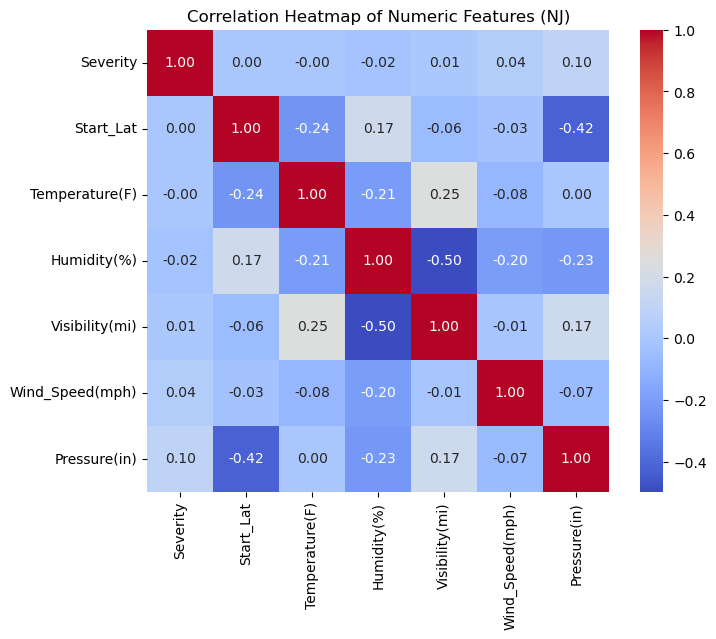

In [21]:
# 1 Correlation Heatmap of Numeric Features
numeric_cols = ['Severity','Start_Lat', 'Temperature(F)', 'Humidity(%)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Pressure(in)']
# numeric_cols = data.select_dtypes(include=[np.number]).columns.tolist()
corr_matrix = data[numeric_cols].dropna().corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", square=True)
plt.title('Correlation Heatmap of Numeric Features (NJ)')
plt.show()

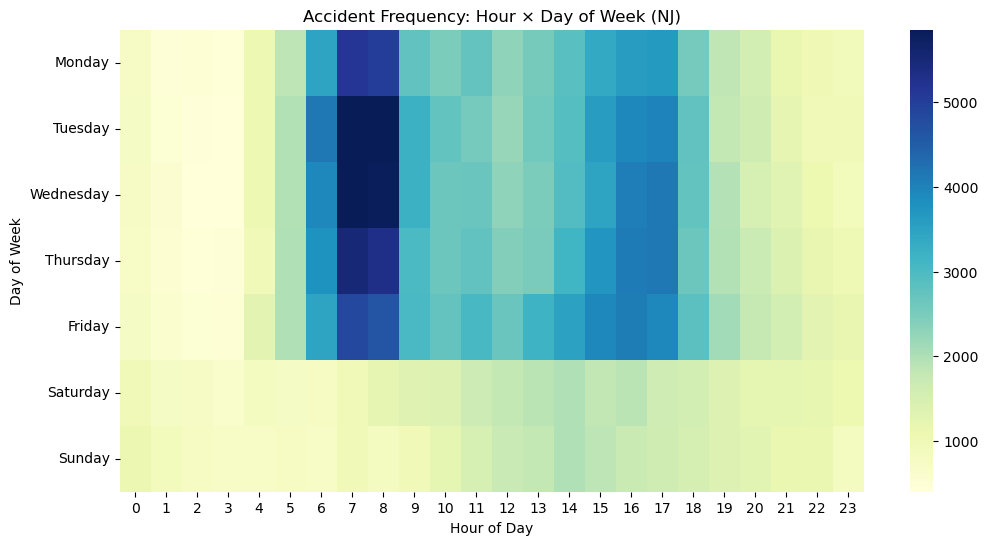

In [22]:
# 2 Pivot Table / Heatmap: Hour × Day of Week
data['Hour'] = data['Start_Time'].dt.hour
data['Weekday'] = data['Start_Time'].dt.dayofweek.map(lambda x: calendar.day_name[x])

pivot_table = data.pivot_table(index='Weekday', columns='Hour', values='ID', aggfunc='count').fillna(0)
pivot_table = pivot_table.reindex(index=list(calendar.day_name))  # Ensure correct weekday order

plt.figure(figsize=(12, 6))
sns.heatmap(pivot_table, cmap='YlGnBu')
plt.title('Accident Frequency: Hour × Day of Week (NJ)')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.show()

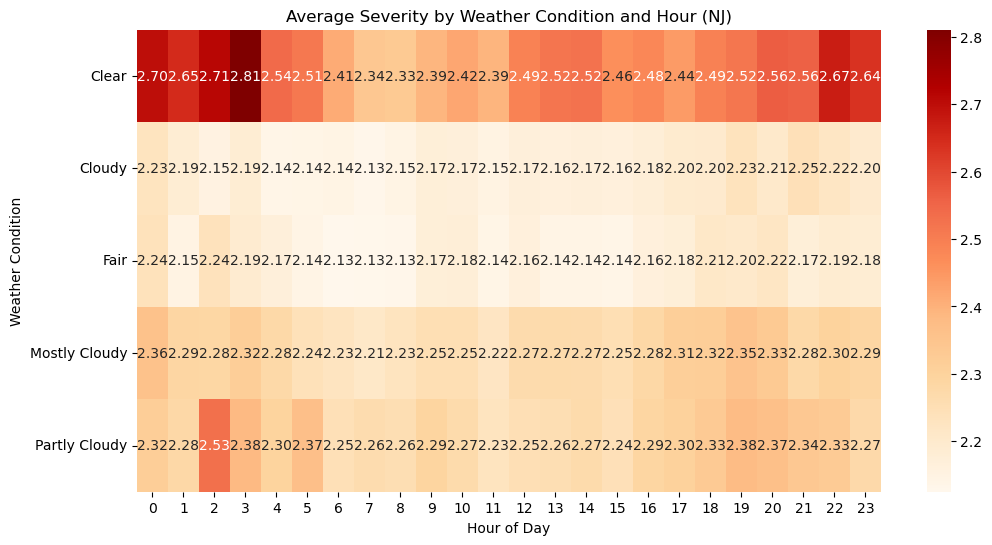

In [23]:
# 3 Combined Effects: Weather + Hour on Severity
# Focus on top 5 weather conditions for clarity
top_weather = data['Weather_Condition'].value_counts().nlargest(5).index
df_combo = data[data['Weather_Condition'].isin(top_weather)]

# Group and average severity
grouped = df_combo.groupby(['Weather_Condition', 'Hour'])['Severity'].mean().unstack()

plt.figure(figsize=(12, 6))
sns.heatmap(grouped, cmap='OrRd', annot=True, fmt=".2f")
plt.title('Average Severity by Weather Condition and Hour (NJ)')
plt.xlabel('Hour of Day')
plt.ylabel('Weather Condition')
plt.show()

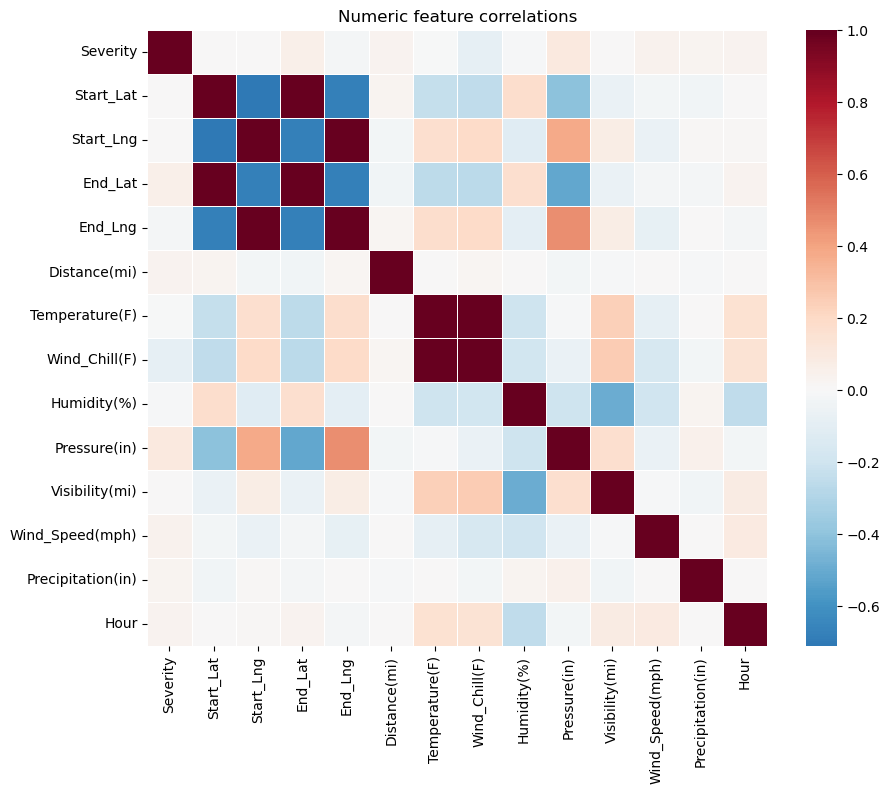


Top 10 Citys:


Bronx            27297
Rochester        24743
New York         21699
Brooklyn         21357
Buffalo           9574
Albany            7403
Staten Island     5806
Flushing          5662
Syracuse          5394
Jamaica           4774
Name: City, dtype: int64


Top 10 Countys:


Queens         41480
Westchester    38224
Monroe         32480
Bronx          27308
Nassau         23325
New York       21989
Suffolk        21828
Kings          21234
Albany         13855
Erie           12818
Name: County, dtype: int64


Top 10 Streets:


I-90 W                   9881
Brooklyn Queens Expy     9549
I-90 E                   8231
Long Island Expy W       7501
Long Island Expy E       7261
I-87 S                   4673
I-87 N                   4013
Southern State Pkwy E    3937
Major Deegan Expy N      3386
Southern State Pkwy W    3365
Name: Street, dtype: int64

In [24]:
# Numeric correlation heatmap (safe selection)
num_cols = data.select_dtypes(include=[np.number]).columns.tolist()
if len(num_cols) > 1:
    corr = data[num_cols].corr()
    plt.figure(figsize=(10,8))
    sns.heatmap(corr, cmap='RdBu_r', center=0, linewidths=.5)
    plt.title('Numeric feature correlations')
    plt.show()
else:
    print('Not enough numeric columns for correlation matrix.')

# Show top counts for City / County / Street if available
for col in ['City','County','Street']:
    if col in data.columns:
        print(f"\nTop 10 {col}s:")
        display(data[col].value_counts().head(10))
    else:
        print(f"Column {col} not found.")


In [25]:
# Create a small folium map sample (saved to HTML)
if 'Start_Lat' in data.columns and 'Start_Lng' in data.columns:
    try:
        sample = data.dropna(subset=['Start_Lat','Start_Lng']).iloc[:500]
        center_lat = sample['Start_Lat'].median()
        center_lng = sample['Start_Lng'].median()
        m = folium.Map(location=[center_lat, center_lng], zoom_start=10)
        for _, r in sample.iterrows():
            folium.CircleMarker([r['Start_Lat'], r['Start_Lng']], radius=2, color='red', fill=True, fill_opacity=0.6).add_to(m)
        out_html = 'data/raw/accidents_map_sample.html'
        m.save(out_html)
        print(f'Saved sample map to {out_html}')
    except Exception as e:
        print('Failed to create folium map:', e)
else:
    print('No Start_Lat/Start_Lng columns found; skipping map creation.')

Saved sample map to data/raw/accidents_map_sample.html


### Data Preparation

In [26]:
# 1 Handle Missing Values
# Drop columns with >50% missing
missing_thresh = 0.5
high_missing_cols = data.columns[data.isnull().mean() > missing_thresh]
data.drop(columns=high_missing_cols, inplace=True)

# Fill numeric columns with median
numeric_cols = data.select_dtypes(include=['float64', 'int64']).columns
for col in numeric_cols:
    data[col].fillna(data[col].median(), inplace=True)

# Fill categorical columns with mode
categorical_cols = data.select_dtypes(include='object').columns
for col in categorical_cols:
    data[col].fillna(data[col].mode()[0], inplace=True)

In [27]:
data.columns

Index(['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat',
       'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description',
       'Street', 'City', 'County', 'State', 'Zipcode', 'Country', 'Timezone',
       'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)',
       'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction',
       'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity',
       'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway',
       'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal',
       'Turning_Loop', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight',
       'Astronomical_Twilight', 'Weekday', 'Hour'],
      dtype='object')

In [28]:
# 2 Feature Engineering from Datetime
data['Hour'] = data['Start_Time'].dt.hour
data['Day'] = data['Start_Time'].dt.day
data['Month'] = data['Start_Time'].dt.month
data['Weekday'] = data['Start_Time'].dt.dayofweek
data['Weekend'] = data['Weekday'].apply(lambda x: 1 if x >= 5 else 0)

# Season mapping
def get_season(month):
    if month in [12, 1, 2]: return 'Winter'
    elif month in [3, 4, 5]: return 'Spring'
    elif month in [6, 7, 8]: return 'Summer'
    else: return 'Fall'
data['Season'] = data['Month'].apply(get_season)

In [29]:
data.columns

Index(['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat',
       'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description',
       'Street', 'City', 'County', 'State', 'Zipcode', 'Country', 'Timezone',
       'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)',
       'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction',
       'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity',
       'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway',
       'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal',
       'Turning_Loop', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight',
       'Astronomical_Twilight', 'Weekday', 'Hour', 'Day', 'Month', 'Weekend',
       'Season'],
      dtype='object')

In [30]:
data['Season'].isnull().sum()

0

In [31]:
# 3 Cap Extreme Outliers
# Accident duration in minutes
data['Duration'] = (data['End_Time'] - data['Start_Time']).dt.total_seconds() / 60

# Cap duration and distance at 99th percentile
duration_cap = data['Duration'].quantile(0.99)
distance_cap = data['Distance(mi)'].quantile(0.99)

data['Duration'] = np.where(data['Duration'] > duration_cap, duration_cap, data['Duration'])
data['Distance(mi)'] = np.where(data['Distance(mi)'] > distance_cap, distance_cap, data['Distance(mi)'])

In [32]:
data['Duration'].describe()

count    347960.000000
mean        115.526912
std         126.420243
min           1.916667
25%          30.200000
50%          76.550000
75%         130.466667
max         780.500000
Name: Duration, dtype: float64

In [33]:
# 4 One-Hot Encoding for Categorical Variables
# Select relevant categorical columns
encode_cols = ['Weather_Condition', 'Season', 'Sunrise_Sunset']
data_encoded = pd.get_dummies(data, columns=encode_cols, drop_first=True)

# Final cleaned dataset
print("Prepared dataset shape:", data_encoded.shape)

Prepared dataset shape: (347960, 139)


○	 Handle missing values (median for numeric, mode for categorical, or dropping high-missing columns).
○	 Convert datetime fields into engineered features (hour, day, month, season, weekend flag).
○	 Cap extreme outliers (e.g., accident duration, distance).
○	 Encode categorical variables (one-hot encoding).


In [34]:
data_nj.shape

(347960, 46)

In [39]:
# Convert datetime



data_nj['Start_Time'] = pd.to_datetime(data_nj['Start_Time'])
data_nj['End_Time'] = pd.to_datetime(data_nj['End_Time'])

# 1 Handle Missing Values
# Drop columns with >50% missing
missing_thresh = 0.5
high_missing_cols = data_nj.columns[data_nj.isnull().mean() > missing_thresh]
data_nj.drop(columns=high_missing_cols, inplace=True)

# Fill numeric columns with median
numeric_cols = data_nj.select_dtypes(include=['float64', 'int64']).columns
for col in numeric_cols:
    data_nj[col].fillna(data_nj[col].median(), inplace=True)

# Fill categorical columns with mode
categorical_cols = data_nj.select_dtypes(include='object').columns
for col in categorical_cols:
    data_nj[col].fillna(data_nj[col].mode()[0], inplace=True)

# 2 Feature Engineering from Datetime
data_nj['Hour'] = data_nj['Start_Time'].dt.hour
data_nj['Day'] = data_nj['Start_Time'].dt.day
data_nj['Month'] = data_nj['Start_Time'].dt.month
data_nj['Weekday'] = data_nj['Start_Time'].dt.dayofweek
data_nj['Weekend'] = data_nj['Weekday'].apply(lambda x: 1 if x >= 5 else 0)

# Season mapping
def get_season(month):
    if month in [12, 1, 2]: return 'Winter'
    elif month in [3, 4, 5]: return 'Spring'
    elif month in [6, 7, 8]: return 'Summer'
    else: return 'Fall'
data_nj['Season'] = data_nj['Month'].apply(get_season)

# 3 Cap Extreme Outliers
# Accident duration in minutes
data_nj['Duration'] = (data_nj['End_Time'] - data_nj['Start_Time']).dt.total_seconds() / 60

# Cap duration and distance at 99th percentile
duration_cap = data_nj['Duration'].quantile(0.99)
distance_cap = data_nj['Distance(mi)'].quantile(0.99)

data_nj['Duration'] = np.where(data_nj['Duration'] > duration_cap, duration_cap, data_nj['Duration'])
data_nj['Distance(mi)'] = np.where(data_nj['Distance(mi)'] > distance_cap, distance_cap, data_nj['Distance(mi)'])

# 4 One-Hot Encoding for Categorical Variables
# Select relevant categorical columns
encode_cols = ['Weather_Condition', 'Season', 'Sunrise_Sunset']
df_nj_encoded = pd.get_dummies(data_nj, columns=encode_cols, drop_first=True)

# Final cleaned dataset
print("Prepared dataset shape:", df_nj_encoded.shape)

Prepared dataset shape: (347960, 139)
